# Drill-String Neutral Point & Drill-Collar Design — Worked Example

This notebook sizes the **drill collars** for a target weight on bit, locates the
**neutral point** (where the string changes from tension above to compression below),
checks the compressed collars against **buckling**, and designs the **drill-pipe
tension** (hook load, margin of overpull, safety factor of tension).

## Problem Statement

Design the bottom-hole assembly and drill-pipe tension for the following vertical well:

| Parameter | Value | Unit |
|---|---|---|
| Well depth | 12,000 | ft |
| Drill pipe weight (air) | 19.5 | lb/ft |
| Drill pipe OD / ID | 5.0 / 4.276 | in |
| Drill pipe tensile strength (new) | 395,600 | lbf |
| Drill collar weight (air) | 115 | lb/ft |
| Drill collar OD / ID | 7.0 / 2.8125 | in |
| Drill collar length available | 700 | ft |
| Mud weight | 11.0 | ppg |
| Target weight on bit (WOB) | 50,000 | lbf |
| Neutral-point factor | 0.85 | – |
| Hole diameter | 8.5 | in |

In [1]:
# Importing libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
# ---- Given well data ----
depth     = 12000.0   # well depth (ft)
w_dp      = 19.5      # drill pipe weight in air (lb/ft)
od_dp     = 5.0       # drill pipe OD (in)
id_dp     = 4.276     # drill pipe ID (in)
pt_dp     = 395600.0  # drill pipe tensile strength, new pipe (lbf)
w_collar  = 115.0     # drill collar weight in air (lb/ft)
od_collar = 7.0       # drill collar OD (in)
id_collar = 2.8125    # drill collar ID (in)
l_collar  = 700.0     # drill collar length available (ft)
mud_ppg   = 11.0      # mud weight (ppg)
wob       = 50000.0   # target weight on bit (lbf)
np_factor = 0.85      # neutral-point factor
hole_in   = 8.5       # hole diameter (in)
inc_deg   = 0.0       # inclination (deg, 0 = vertical)
E_steel   = 30.0e6    # Young's modulus of steel (psi)

inputs = pd.DataFrame({
    'Parameter': ['Well depth','Drill pipe weight','Drill pipe OD','Drill pipe ID',
                  'Drill pipe tensile strength','Drill collar weight','Drill collar OD',
                  'Drill collar ID','Drill collar length','Mud weight','Weight on bit',
                  'Neutral-point factor','Hole diameter'],
    'Value': [depth,w_dp,od_dp,id_dp,pt_dp,w_collar,od_collar,id_collar,
              l_collar,mud_ppg,wob,np_factor,hole_in],
    'Unit':  ['ft','lb/ft','in','in','lbf','lb/ft','in','in','ft','ppg','lbf','-','in'],
})
inputs

,Parameter,Value,Unit
0,Well depth,12000.0000,ft
1,Drill pipe weight,19.5000,lb/ft
2,Drill pipe OD,5.0000,in
3,Drill pipe ID,4.2760,in
4,Drill pipe tensile strength,395600.0000,lbf
5,Drill collar weight,115.0000,lb/ft
6,Drill collar OD,7.0000,in
7,Drill collar ID,2.8125,in
8,Drill collar length,700.0000,ft
9,Mud weight,11.0000,ppg


## Method

**Buoyancy factor** — the fraction of air weight left once the string is in mud:

$$B = 1 - \frac{MW}{65.5}$$

**Drill-collar length** — enough collars so the neutral point sits part-way up them
(the neutral-point factor $NP$ keeps it below the top), rounded up to one 30-ft stand:

$$L_C = \frac{WOB}{\cos\alpha \cdot NP \cdot B \cdot w_c}$$

**Neutral point** — height above the bit where the buoyed collar weight below equals
the WOB; this is where the effective (stability) force crosses zero:

$$h_{NP} = \frac{WOB}{w_c \cdot B \cdot \cos\alpha}$$

**Buckling of the compressed collars** — sinusoidal (snaking) then helical (locked helix):

$$F_{cr,s} = 2\sqrt{\frac{E\,I\,w_e}{r}}, \qquad F_{cr,h} = 2\sqrt{2}\,\sqrt{\frac{E\,I\,w_e}{r}}$$

**Drill-pipe tension** — off-bottom the hook carries the whole buoyed string; on bottom
the top joint carries that minus the WOB resting on the bit:

$$P_a = 0.9\,P_t, \qquad SFT = \frac{P_a}{T_{top}}, \qquad MOP = P_a - T_{top}$$

In [3]:
# Buoyancy factor
bf = 1.0 - mud_ppg / 65.5
cos_i = np.cos(np.radians(inc_deg))
print(f'Buoyancy factor B = {bf:.4f}')

Buoyancy factor B = 0.8321


In [4]:
# Drill-collar length (rounded up to the next 30-ft stand)
lc_raw  = wob / (cos_i * np_factor * bf * w_collar)
lc_need = np.ceil(lc_raw / 30.0) * 30.0
wob_max = cos_i * np_factor * bf * w_collar * l_collar
print(f'Collar length needed  = {lc_need:,.0f} ft  (have {l_collar:,.0f} ft)')
print(f'Max WOB these collars = {wob_max:,.0f} lbf')

Collar length needed  = 630 ft  (have 700 ft)
Max WOB these collars = 56,934 lbf


In [5]:
# Neutral point above the bit
np_height = wob / (w_collar * bf * cos_i)
pct = np_height / l_collar * 100
print(f'Neutral point = {np_height:,.0f} ft above bit  ({pct:.0f}% up the collars)')

Neutral point = 523 ft above bit  (75% up the collars)


In [6]:
# String makeup (buoyed weights)
l_dp          = depth - l_collar
n_collars     = l_collar / 30.0
w_collar_buoy = l_collar * w_collar * bf
w_dp_buoy     = l_dp * w_dp * bf
w_string_buoy = w_collar_buoy + w_dp_buoy
print(f'Drill collars : {l_collar:,.0f} ft ({n_collars:.0f} x 30 ft), {w_collar_buoy:,.0f} lbf buoyed')
print(f'Drill pipe    : {l_dp:,.0f} ft, {w_dp_buoy:,.0f} lbf buoyed')
print(f'Buoyed string weight = {w_string_buoy:,.0f} lbf')

Drill collars : 700 ft (23 x 30 ft), 66,981 lbf buoyed
Drill pipe    : 11,300 ft, 183,345 lbf buoyed
Buoyed string weight = 250,326 lbf


In [7]:
# Buckling check (sinusoidal and helical)
I_collar = np.pi / 64.0 * (od_collar**4 - id_collar**4)
we       = w_collar * bf / 12.0
r_clear  = (hole_in - od_collar) / 2.0
fcr_s = 2.0 * np.sqrt(E_steel * I_collar * we / r_clear)
fcr_h = 2.0 * np.sqrt(2.0) * np.sqrt(E_steel * I_collar * we / r_clear)
print(f'Compression at bit = WOB = {wob:,.0f} lbf')
print(f'Sinusoidal Fcr,s = {fcr_s:,.0f} lbf  -> {"OK" if wob < fcr_s else "BUCKLES"}')
print(f'Helical    Fcr,h = {fcr_h:,.0f} lbf  -> {"OK" if wob < fcr_h else "BUCKLES"}')

Compression at bit = WOB = 50,000 lbf
Sinusoidal Fcr,s = 382,686 lbf  -> OK
Helical    Fcr,h = 541,200 lbf  -> OK


In [8]:
# Drill-pipe tension design
hook_load   = w_string_buoy                 # off-bottom hook load
tension_top = w_string_buoy - wob           # top-joint load on bottom
pa          = 0.9 * pt_dp                    # allowable load
sft         = pa / tension_top
mop         = pa - tension_top
print(f'Off-bottom hook load       = {hook_load:,.0f} lbf')
print(f'Top-joint load (on bottom) = {tension_top:,.0f} lbf')
print(f'Allowable load Pa (0.9 Pt) = {pa:,.0f} lbf')
print(f'Safety factor of tension   = {sft:.2f}')
print(f'Margin of overpull         = {mop:,.0f} lbf')

Off-bottom hook load       = 250,326 lbf
Top-joint load (on bottom) = 200,326 lbf
Allowable load Pa (0.9 Pt) = 356,040 lbf
Safety factor of tension   = 1.78
Margin of overpull         = 155,714 lbf


## Results Summary

In [9]:
summary = pd.DataFrame({
    'Quantity': ['Buoyancy factor','Collar length needed','Neutral point above bit',
                 'Buoyed string weight','Sinusoidal buckling load','Helical buckling load',
                 'Top-joint tension','Safety factor of tension','Margin of overpull'],
    'Value': [round(bf,4), round(lc_need), round(np_height), round(w_string_buoy),
              round(fcr_s), round(fcr_h), round(tension_top), round(sft,2), round(mop)],
    'Unit':  ['-','ft','ft','lbf','lbf','lbf','lbf','-','lbf'],
})
summary

,Quantity,Value,Unit
0,Buoyancy factor,0.8321,-
1,Collar length needed,630.0000,ft
2,Neutral point above bit,523.0000,ft
3,Buoyed string weight,250326.0000,lbf
4,Sinusoidal buckling load,382686.0000,lbf
5,Helical buckling load,541200.0000,lbf
6,Top-joint tension,200326.0000,lbf
7,Safety factor of tension,1.7800,-
8,Margin of overpull,155714.0000,lbf


## Design Checks

Each design criterion is checked against its limit.

In [10]:
checks = pd.DataFrame({
    'Check': ['Collars long enough for WOB','Neutral point inside collars',
              'No sinusoidal buckling','No helical buckling','Tension safety factor >= 1.3'],
    'Criterion': [f'L_C needed {lc_need:,.0f} <= {l_collar:,.0f} ft',
                  f'{np_height:,.0f} <= {l_collar:,.0f} ft',
                  f'WOB {wob:,.0f} < {fcr_s:,.0f} lbf',
                  f'WOB {wob:,.0f} < {fcr_h:,.0f} lbf',
                  f'SFT {sft:.2f} >= 1.3'],
    'Status': ['PASS' if l_collar >= lc_need else 'FAIL',
               'PASS' if np_height <= l_collar else 'FAIL',
               'PASS' if wob < fcr_s else 'FAIL',
               'PASS' if wob < fcr_h else 'FAIL',
               'PASS' if sft >= 1.3 else 'FAIL'],
})
checks

,Check,Criterion,Status
0,Collars long enough for WOB,L_C needed 630 <= 700 ft,PASS
1,Neutral point inside collars,523 <= 700 ft,PASS
2,No sinusoidal buckling,"WOB 50,000 < 382,686 lbf",PASS
3,No helical buckling,"WOB 50,000 < 541,200 lbf",PASS
4,Tension safety factor >= 1.3,SFT 1.78 >= 1.3,PASS


## Axial Force vs Depth

The **effective force** starts at $-WOB$ at the bit and builds up on buoyed weight; it
governs buckling and defines the neutral point. The **real axial force** is the effective
force minus the pressure–area term, so it reads much more compressive near the bottom.

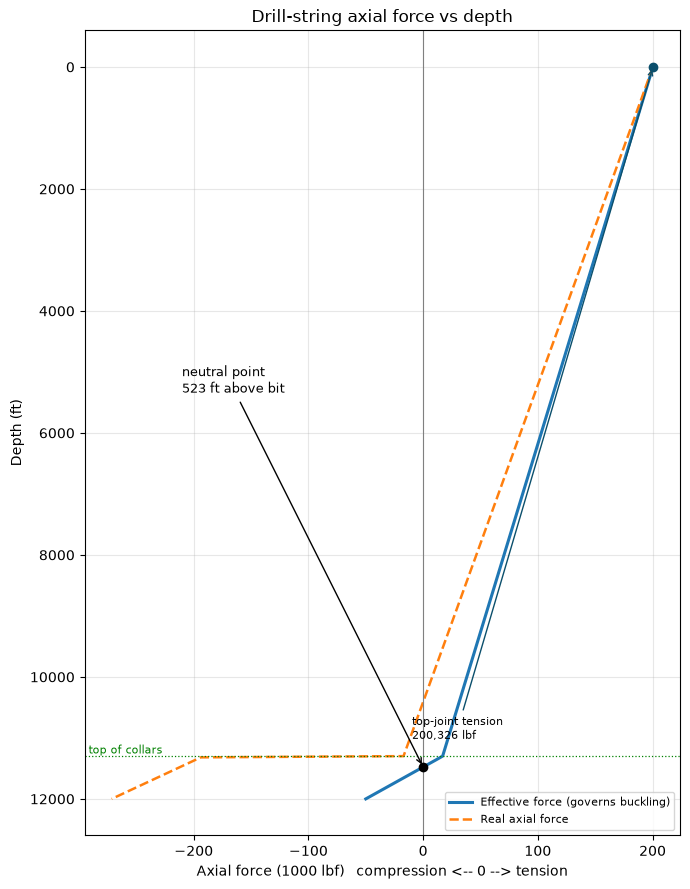

In [11]:
a_steel_collar = np.pi/4.0 * (od_collar**2 - id_collar**2)
a_steel_dp     = np.pi/4.0 * (od_dp**2 - id_dp**2)
top_of_collar  = depth - l_collar

z = np.linspace(0.0, depth, 600)
f_eff = np.zeros_like(z); a_st = np.zeros_like(z)
for k, zk in enumerate(z):
    if zk >= top_of_collar:
        f_eff[k] = -wob + (depth - zk) * w_collar * bf
        a_st[k]  = a_steel_collar
    else:
        f_eff[k] = -wob + l_collar*w_collar*bf + (top_of_collar - zk)*w_dp*bf
        a_st[k]  = a_steel_dp
f_real = f_eff - 0.052 * mud_ppg * z * a_st

plt.figure(figsize=(7,9))
plt.plot(f_eff/1000.0, z, lw=2.2, label='Effective force (governs buckling)')
plt.plot(f_real/1000.0, z, lw=1.8, ls='--', label='Real axial force')
plt.axvline(0, color='grey', lw=0.8)

np_depth = depth - np_height
plt.scatter([0], [np_depth], color='black', zorder=5)
plt.annotate(f'  neutral point\n  {np_height:,.0f} ft above bit',
             xy=(0, np_depth), xytext=(0.15, 0.55), textcoords='axes fraction',
             fontsize=9, arrowprops=dict(arrowstyle='->', color='black'))

plt.axhline(top_of_collar, color='green', lw=0.9, ls=':')
plt.text(plt.xlim()[0], top_of_collar, ' top of collars', va='bottom', fontsize=8, color='green')

plt.scatter([tension_top/1000.0], [0.0], color='#0b4f6c', zorder=5)
plt.annotate(f'top-joint tension\n{tension_top:,.0f} lbf',
             xy=(tension_top/1000.0, 0.0), xytext=(0.55, 0.12), textcoords='axes fraction',
             fontsize=8, arrowprops=dict(arrowstyle='->', color='#0b4f6c'))

plt.gca().invert_yaxis()
plt.xlabel('Axial force (1000 lbf)   compression <-- 0 --> tension')
plt.ylabel('Depth (ft)')
plt.title('Drill-string axial force vs depth')
plt.grid(alpha=0.3); plt.legend(loc='lower right', fontsize=8)
plt.tight_layout()
plt.show()

## Conclusion

A **630 ft** drill-collar string carries the 50,000 lbf WOB with the neutral point
**523 ft above the bit**, well inside the collars, so the drill pipe stays in tension
throughout. The collars are far from buckling (WOB is only ~13% of the sinusoidal limit),
and the top joint of drill pipe runs at a **safety factor of 1.78** with **~156,000 lbf**
of overpull in reserve for freeing stuck pipe.